# Segmentation-Guided Explainable Hybrid Deep Learning Framework for Multi-Class Thoracic Disease Classification from Chest Radiographs

## Notebook 01 : Data Exploration

Author : Solomon Rajan P

Dataset : NIH ChestX-ray14

Objective:
- Load NIH Chest X-ray dataset
- Read metadata
- Explore disease distribution
- Display sample images
- Analyze class imbalance
- Prepare dataset for preprocessing

# 01 Data Exploration

Dataset:
NIH ChestX-ray14

Purpose:
To understand the structure, class distribution, missing values,
and image availability before preprocessing.

Expected Output

• Dataset statistics
• Disease frequency
• Sample chest X-rays
• Data quality analysis

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm import tqdm

plt.style.use("ggplot")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================
# SegFusionFormer - Project Configuration
# ============================================

from pathlib import Path
import sys

# Find the project root directory
current_path = Path.cwd().resolve()

project_path = next(
    (
        path for path in
        (current_path, *current_path.parents)
        if (path / "config.py").is_file()
    ),
    None
)

if project_path is None:
    raise FileNotFoundError(
        "config.py not found. "
        "Open the notebook from the SegFusionFormer project."
    )

# Add project directory to Python path
if str(project_path) not in sys.path:
    sys.path.insert(0, str(project_path))

# Import centralized configuration
from config import (
    PROJECT_ROOT,
    DATASET_DIR,
    IMAGE_DIR,
    METADATA_CSV,
    BBOX_CSV
)

# Preserve existing variable names
project_root = str(PROJECT_ROOT)
dataset_path = str(DATASET_DIR)
image_folder = str(IMAGE_DIR)
csv_file = str(METADATA_CSV)
bbox_file = str(BBOX_CSV)

# Display project configuration
print("=" * 50)
print("SegFusionFormer - Dataset Configuration")
print("=" * 50)

print("Project Root:", project_root)
print("Dataset Folder:", dataset_path)
print("Images Folder:", image_folder)
print("Metadata CSV:", csv_file)
print("Bounding Box CSV:", bbox_file)

# Verify dataset locations
print("\nDataset Verification")
print("Dataset Exists:", DATASET_DIR.exists())
print("Images Exist:", IMAGE_DIR.exists())
print("Metadata Exists:", METADATA_CSV.exists())

print("\nConfiguration loaded successfully!")

Notebook Location:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/notebooks

Project Root:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer

Dataset Path:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset

Images Folder:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images

CSV File:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/Data_Entry_2017.csv

BBox File:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/BBox_List_2017.csv


In [4]:
import pandas as pd

df = pd.read_csv(csv_file)

print("Dataset Loaded Successfully")
print()

df.head()

Dataset Loaded Successfully



,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


In [5]:
print("Dataset Shape :", df.shape)

Dataset Shape : (112120, 12)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  str    
 1   Finding Labels               112120 non-null  str    
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Gender               112120 non-null  str    
 6   View Position                112120 non-null  str    
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
 11  Unnamed: 11                  0 non-null       float64
dtypes: float64(3), int64(5), str(4)
memory usage: 10.3 MB


In [7]:
df.isnull().sum()

Image Index                         0
Finding Labels                      0
Follow-up #                         0
Patient ID                          0
Patient Age                         0
Patient Gender                      0
View Position                       0
OriginalImage[Width                 0
Height]                             0
OriginalImagePixelSpacing[x         0
y]                                  0
Unnamed: 11                    112120
dtype: int64

In [8]:
image_files = os.listdir(image_folder)

print("Total Images Found :", len(image_files))

Total Images Found : 112121


In [9]:
missing_images = []

for img in df["Image Index"]:
    img_path = os.path.join(image_folder, img)

    if not os.path.exists(img_path):
        missing_images.append(img)

print("Missing Images :", len(missing_images))

Missing Images : 0


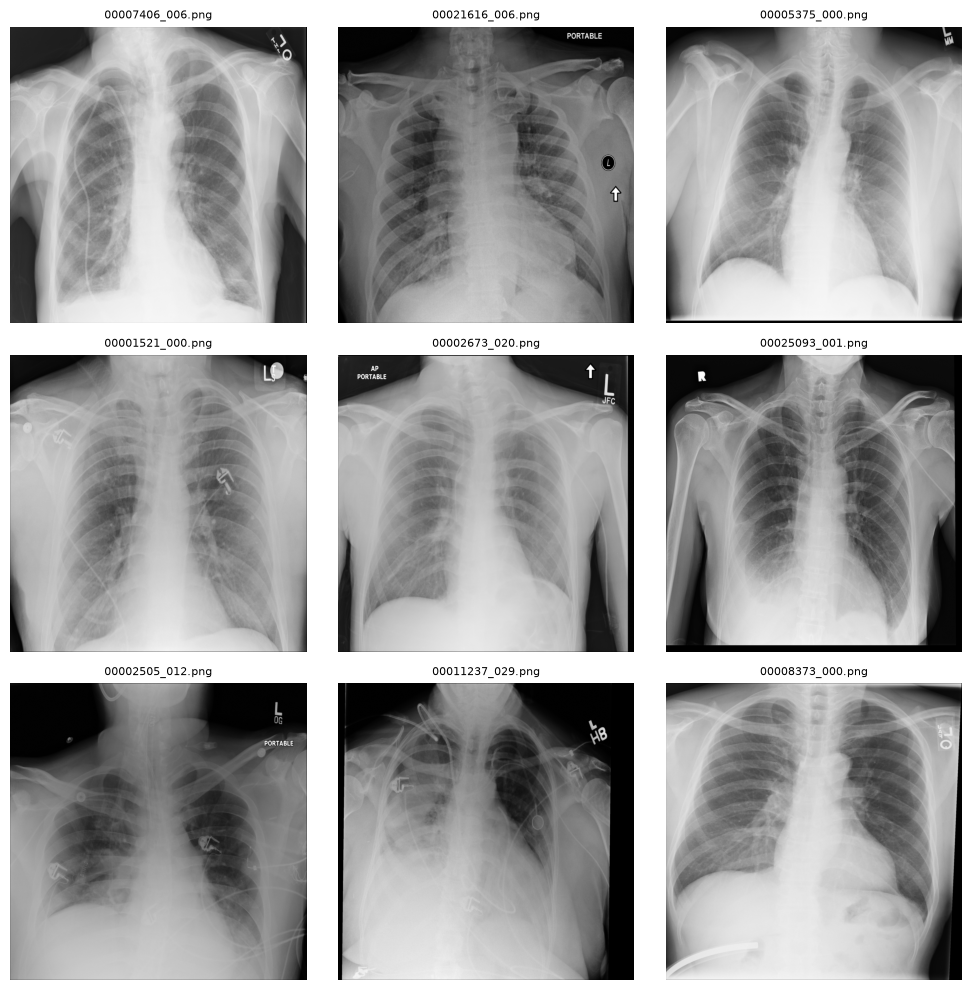

In [10]:
import matplotlib.pyplot as plt
from PIL import Image
import random

sample_images = random.sample(list(df["Image Index"]), 9)

plt.figure(figsize=(10,10))

for i, img_name in enumerate(sample_images):
    img = Image.open(os.path.join(image_folder, img_name))

    plt.subplot(3,3,i+1)
    plt.imshow(img, cmap="gray")
    plt.title(img_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
disease_counts = df["Finding Labels"].str.split("|").explode().value_counts()

print(disease_counts)

Finding Labels
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Name: count, dtype: int64


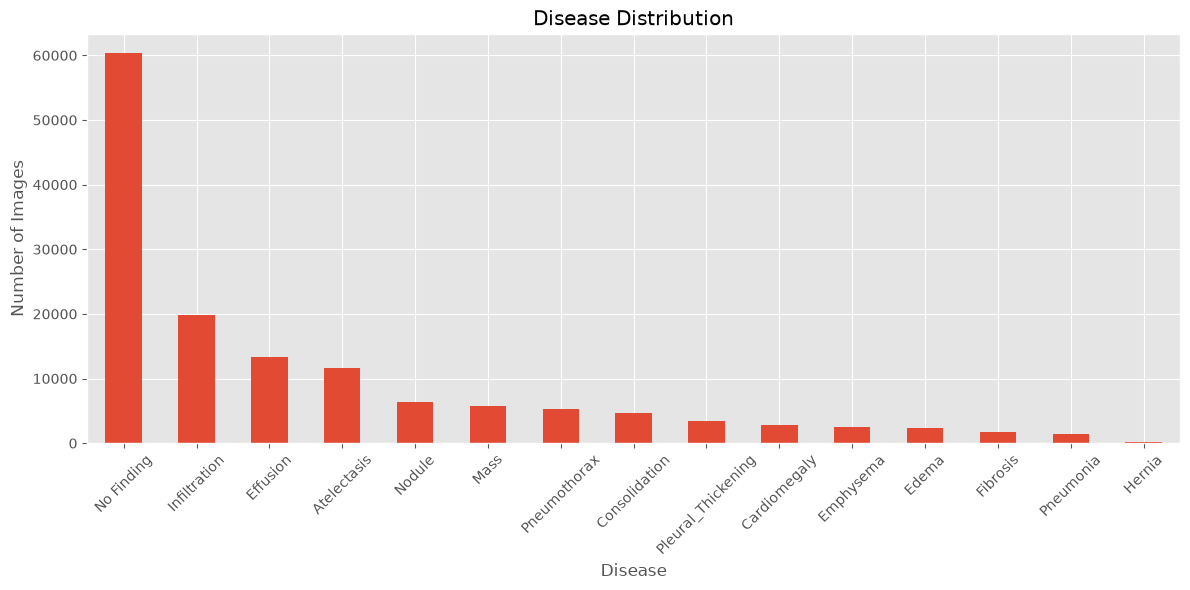

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

disease_counts.plot(kind="bar")

plt.title("Disease Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [13]:
df = df.drop(columns=["Unnamed: 11"])

print(df.shape)

(112120, 11)
